# AHCD: Data Exploration for the Project Proposal

This notebook loads the Arabic Handwritten Characters Dataset (AHCD), checks the data,
produces the two figures required for the proposal, and creates the train/validation split.

**Before running:** extract the Kaggle zip and put the four CSV files inside a folder named `data/`
next to this notebook. The code searches `data/` (including subfolders), so the exact
subfolder name does not matter.

Outputs:
- `figures/samples.png`: sample grid, one example per letter
- `figures/class_distribution.png`: samples per class (train and test)
- `figures/mean_images.png`: average image per letter (optional extra)
- `splits/train_idx.csv`, `splits/val_idx.csv`: the fixed validation split
- `results/dataset_summary.csv`: numbers for the proposal

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
VAL_FRACTION = 0.15
DATA_DIR = "data"

for d in ["figures", "splits", "results"]:
    os.makedirs(d, exist_ok=True)

# Letter names in AHCD label order (label 1 = alef, ..., label 28 = yeh)
LETTERS = [
    "alef", "beh", "teh", "theh", "jeem", "hah", "khah", "dal", "thal", "reh",
    "zain", "seen", "sheen", "sad", "dad", "tah", "zah", "ain", "ghain", "feh",
    "qaf", "kaf", "lam", "meem", "noon", "heh", "waw", "yeh",
]
ARABIC = list("ابتثجحخدذرزسشصضطظعغفقكلمنهوي")

Matplotlib is building the font cache; this may take a moment.


## 1. Load the data

The CSV files have no header row. Each image row holds 1024 pixel values (a flattened 32×32 image),
and each label row holds one number from 1 to 28.

In [2]:
def find_csv(*keywords):
    """Find the one CSV under DATA_DIR whose name contains all keywords (case-insensitive)."""
    paths = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
    matches = [p for p in paths if all(k in os.path.basename(p).lower() for k in keywords)]
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one CSV matching {keywords} in '{DATA_DIR}/', found: {matches}\n"
            f"CSV files found: {paths}"
        )
    return matches[0]

paths = {
    "X_train": find_csv("train", "image"),
    "y_train": find_csv("train", "label"),
    "X_test":  find_csv("test", "image"),
    "y_test":  find_csv("test", "label"),
}
for k, p in paths.items():
    print(f"{k:8s} -> {p}")

X_train = pd.read_csv(paths["X_train"], header=None).values.astype(np.uint8)
y_train = pd.read_csv(paths["y_train"], header=None).values.ravel()
X_test  = pd.read_csv(paths["X_test"],  header=None).values.astype(np.uint8)
y_test  = pd.read_csv(paths["y_test"],  header=None).values.ravel()

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape,  " y_test: ", y_test.shape)

X_train  -> data\Arabic Handwritten Characters Dataset CSV\csvTrainImages 13440x1024.csv
y_train  -> data\Arabic Handwritten Characters Dataset CSV\csvTrainLabel 13440x1.csv
X_test   -> data\Arabic Handwritten Characters Dataset CSV\csvTestImages 3360x1024.csv
y_test   -> data\Arabic Handwritten Characters Dataset CSV\csvTestLabel 3360x1.csv
X_train: (13440, 1024)  y_train: (13440,)
X_test:  (3360, 1024)  y_test:  (3360,)


## 2. Sanity checks

In [3]:
print("Pixel range:", X_train.min(), "to", X_train.max())
print("Label range:", y_train.min(), "to", y_train.max(), "| unique labels:", len(np.unique(y_train)))
print("Missing values:", int(pd.isna(X_train).sum() + pd.isna(X_test).sum()))

# Exact duplicate images inside the training set, and images shared between train and test
train_hashes = pd.Series([r.tobytes() for r in X_train])
test_hashes = pd.Series([r.tobytes() for r in X_test])
print("Duplicate images within train:", int(train_hashes.duplicated().sum()))
print("Test images that also appear in train:", int(test_hashes.isin(set(train_hashes)).sum()))

# Convert labels 1..28 to 0..27 for Python indexing
if y_train.min() == 1:
    y_train = y_train - 1
    y_test = y_test - 1

Pixel range: 0 to 255
Label range: 1 to 28 | unique labels: 28
Missing values: 0
Duplicate images within train: 0
Test images that also appear in train: 0


## 3. Reshape into images

AHCD stores each image column by column, so a plain reshape gives rotated/mirrored letters.
Transposing fixes this. **Look at the grid in the next step:** if the letters still look wrong,
change `TRANSPOSE` and run again.

In [4]:
TRANSPOSE = True

def to_images(X):
    imgs = X.reshape(-1, 32, 32)
    return imgs.transpose(0, 2, 1) if TRANSPOSE else imgs

train_imgs = to_images(X_train)
test_imgs = to_images(X_test)
print(train_imgs.shape, test_imgs.shape)

(13440, 32, 32) (3360, 32, 32)


## 4. Figure 1: sample grid (one example per letter)

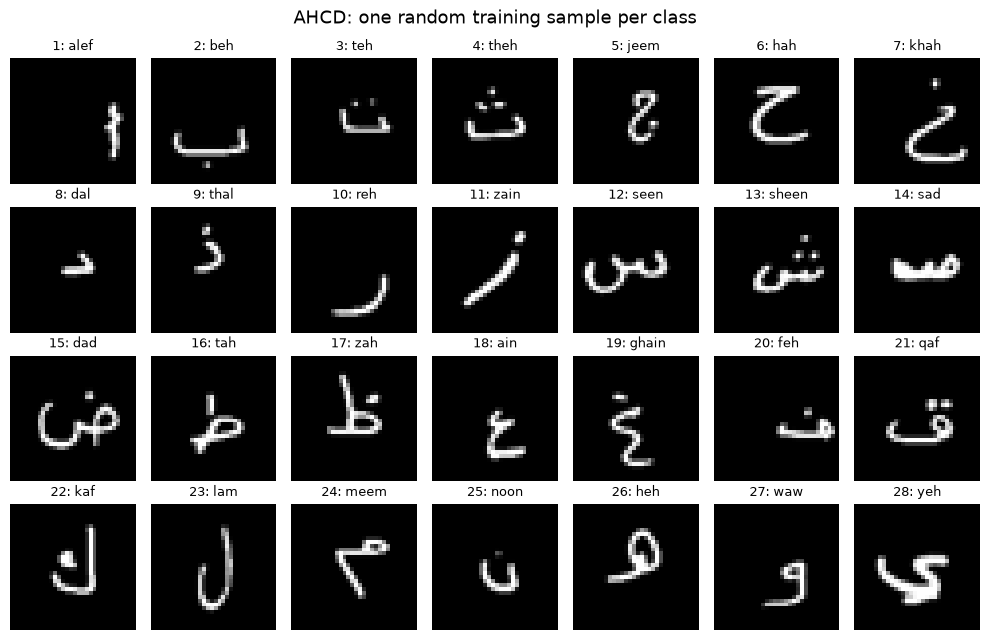

In [5]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 7, figsize=(10, 6.5))
for c, ax in enumerate(axes.flat):
    idx = rng.choice(np.where(y_train == c)[0])
    ax.imshow(train_imgs[idx], cmap="gray")
    ax.set_title(f"{c + 1}: {LETTERS[c]}", fontsize=9)
    ax.axis("off")
fig.suptitle("AHCD: one random training sample per class", fontsize=13)
plt.tight_layout()
plt.savefig("figures/samples.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Figure 2: class distribution

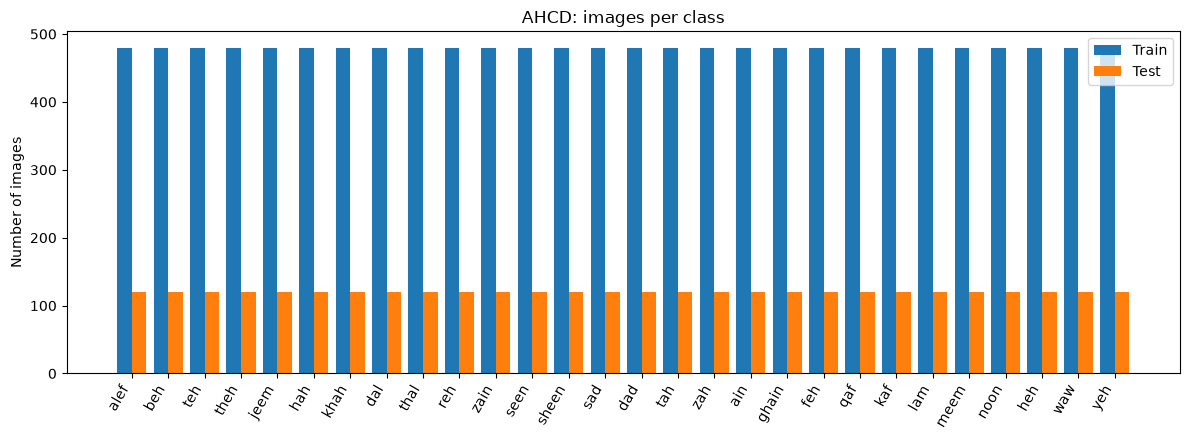

Train per class: min 480 max 480
Test per class:  min 120 max 120
Imbalance ratio (max/min, train): 1.0


In [6]:
train_counts = np.bincount(y_train, minlength=28)
test_counts = np.bincount(y_test, minlength=28)

x = np.arange(28)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - 0.2, train_counts, width=0.4, label="Train")
ax.bar(x + 0.2, test_counts, width=0.4, label="Test")
ax.set_xticks(x)
ax.set_xticklabels(LETTERS, rotation=60, ha="right")
ax.set_ylabel("Number of images")
ax.set_title("AHCD: images per class")
ax.legend()
plt.tight_layout()
plt.savefig("figures/class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print("Train per class: min", train_counts.min(), "max", train_counts.max())
print("Test per class:  min", test_counts.min(), "max", test_counts.max())
print("Imbalance ratio (max/min, train):", round(train_counts.max() / train_counts.min(), 2))

## 6. Optional extra figure: average image per letter

Averaging all images of a class shows the typical shape and how much writers vary.
Blurry averages mean more variation.

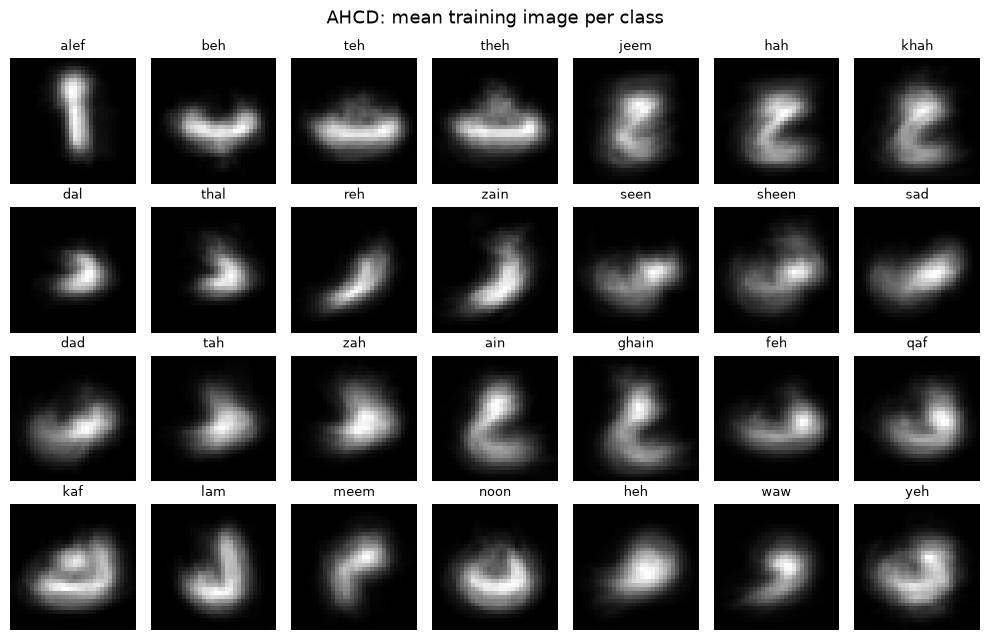

In [7]:
fig, axes = plt.subplots(4, 7, figsize=(10, 6.5))
for c, ax in enumerate(axes.flat):
    ax.imshow(train_imgs[y_train == c].mean(axis=0), cmap="gray")
    ax.set_title(LETTERS[c], fontsize=9)
    ax.axis("off")
fig.suptitle("AHCD: mean training image per class", fontsize=13)
plt.tight_layout()
plt.savefig("figures/mean_images.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Train / validation / test split

- **Test:** the official AHCD test set, kept untouched until final evaluation.
- **Validation:** 15% of the official training set, stratified by class, seed 42.
- **Train:** the remaining 85%.

The indices are saved so every team member (and every later model) uses the exact same split.

In [8]:
all_idx = np.arange(len(y_train))
train_idx, val_idx = train_test_split(
    all_idx, test_size=VAL_FRACTION, stratify=y_train, random_state=SEED
)
pd.Series(np.sort(train_idx), name="index").to_csv("splits/train_idx.csv", index=False)
pd.Series(np.sort(val_idx), name="index").to_csv("splits/val_idx.csv", index=False)

split_table = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "images": [len(train_idx), len(val_idx), len(y_test)],
    "per_class_min": [np.bincount(y_train[train_idx]).min(),
                      np.bincount(y_train[val_idx]).min(), test_counts.min()],
    "per_class_max": [np.bincount(y_train[train_idx]).max(),
                      np.bincount(y_train[val_idx]).max(), test_counts.max()],
})
total = split_table["images"].sum()
split_table["percent"] = (100 * split_table["images"] / total).round(1)
split_table

,split,images,per_class_min,per_class_max,percent
0,train,11424,408,408,68.0
1,validation,2016,72,72,12.0
2,test,3360,120,120,20.0


## 8. Summary numbers for the proposal

In [9]:
summary = pd.DataFrame({
    "item": [
        "Total images", "Official train images", "Official test images",
        "Image size", "Channels", "Pixel value range", "Number of classes",
        "Images per class (train)", "Images per class (test)",
        "Train / val / test after split",
    ],
    "value": [
        len(y_train) + len(y_test), len(y_train), len(y_test),
        "32 x 32", "1 (grayscale)", f"{X_train.min()} to {X_train.max()}", 28,
        f"{train_counts.min()} to {train_counts.max()}",
        f"{test_counts.min()} to {test_counts.max()}",
        " / ".join(str(n) for n in split_table["images"]),
    ],
})
summary.to_csv("results/dataset_summary.csv", index=False)
summary

,item,value
0,Total images,16800
1,Official train images,13440
2,Official test images,3360
3,Image size,32 x 32
4,Channels,1 (grayscale)
5,Pixel value range,0 to 255
6,Number of classes,28
7,Images per class (train),480 to 480
8,Images per class (test),120 to 120
9,Train / val / test after split,11424 / 2016 / 3360


In [10]:
# Letter table (Arabic + transliteration) to paste into the proposal if useful
pd.DataFrame({"label": range(1, 29), "letter": ARABIC, "name": LETTERS,
              "train": train_counts, "test": test_counts})

,label,letter,name,train,test
0,1,ا,alef,480,120
1,2,ب,beh,480,120
2,3,ت,teh,480,120
3,4,ث,theh,480,120
4,5,ج,jeem,480,120
5,6,ح,hah,480,120
6,7,خ,khah,480,120
7,8,د,dal,480,120
8,9,ذ,thal,480,120
9,10,ر,reh,480,120
